In [2]:
import pandas as pd
import numpy as np
print("libaries imported successfully")

libaries imported successfully


In [7]:
df= pd.read_csv("c:/Users/ROHAN/Downloads/D61. Wardwise Covid beds_3_cleaned.csv")
df.head()

,City Name,Area Name,Day-Month-Year,Ward No.,Ward Name,Type of hospital_PrivateorPublic,Longitude,Latitude,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD
0,Kalyan Dombivali,DOMBIVLI West,44573,63,Kopar Road,Apurva Hospital Private,73.13,19.236,15.0,NaN,NaN,NaN
1,Kalyan Dombivali,DOMBIVLI West,44573,61,Vishnu Nagar,Life Line Hospital Private,73.13,19.236,23.0,NaN,6.0,NaN
2,Kalyan Dombivali,DOMBIVLI West,44573,61,Vishnu Nagar,Apex Hospital Private,73.13,19.236,26.0,NaN,4.0,1.0
3,Kalyan Dombivali,DOMBIVLI West,44573,61,Vishnu Nagar,Apple Hospital Private,73.13,19.236,27.0,10.0,9.0,3.0
4,Kalyan Dombivali,DOMBIVLI West,44573,59,Kanhoji Jedhe Maidan,Spandan Hospital Private,73.13,19.236,22.0,8.0,4.0,NaN


In [14]:
print("Dataset Shape", df.shape)
print("\nColumn Names:")
print(df.columns)
print("\nDataset Information:")
df.info()

Dataset Shape (182, 12)

Column Names:
Index(['City Name', 'Area Name', 'Day-Month-Year', 'Ward No.', 'Ward Name',
       'Type of hospital_PrivateorPublic', 'Longitude', 'Latitude',
       'Total no. of beds', 'Number of COVID beds', 'Number of ICU beds',
       'Number of ventilators or ABD'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   City Name                         181 non-null    str    
 1   Area Name                         179 non-null    str    
 2   Day-Month-Year                    176 non-null    str    
 3   Ward No.                          169 non-null    str    
 4   Ward Name                         179 non-null    str    
 5   Type of hospital_PrivateorPublic  168 non-null    str    
 6   Longitude                         111 non-null    str    
 

In [17]:
# DataFrame 1: Hospital details

hospital_data = df[
    [
        'Ward No.',
        'Ward Name',
        'Type of hospital_PrivateorPublic',
        'Total no. of beds',
        'Number of COVID beds',
        'Number of ICU beds',
        'Number of ventilators or ABD'
    ]
].copy()

# DataFrame 2: Ward details

ward_data = df[
    [
        'Ward No.',
        'Ward Name',
        'Area Name',
        'City Name',
        'Longitude',
        'Latitude'
    ]
].drop_duplicates().copy()

In [19]:
print("Hospital Data:")
display(hospital_data.head())

print("\nWard Data:")
display(ward_data.head())

Hospital Data:


,Ward No.,Ward Name,Type of hospital_PrivateorPublic,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD
0,63,Kopar Road,Apurva Hospital Private,15.0,NaN,NaN,NaN
1,61,Vishnu Nagar,Life Line Hospital Private,23.0,NaN,6.0,NaN
2,61,Vishnu Nagar,Apex Hospital Private,26.0,NaN,4.0,1.0
3,61,Vishnu Nagar,Apple Hospital Private,27.0,10.0,9.0,3.0
4,59,Kanhoji Jedhe Maidan,Spandan Hospital Private,22.0,8.0,4.0,NaN



Ward Data:


,Ward No.,Ward Name,Area Name,City Name,Longitude,Latitude
0,63,Kopar Road,DOMBIVLI West,Kalyan Dombivali,73.13,19.236
1,61,Vishnu Nagar,DOMBIVLI West,Kalyan Dombivali,73.13,19.236
4,59,Kanhoji Jedhe Maidan,DOMBIVLI West,Kalyan Dombivali,73.13,19.236
7,61,Vishnu Nagar,DOMBIVLI West,Kalyan Dombivali,NaN,NaN
9,63,Kopar Road,DOMBIVLI West,Kalyan Dombivali,NaN,NaN


In [22]:
inner_join=pd.merge(hospital_data,ward_data,on=['Ward No.','Ward Name'],how='inner')
display(inner_join.head())

,Ward No.,Ward Name,Type of hospital_PrivateorPublic,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD,Area Name,City Name,Longitude,Latitude
0,63,Kopar Road,Apurva Hospital Private,15.0,NaN,NaN,NaN,DOMBIVLI West,Kalyan Dombivali,73.13,19.236
1,63,Kopar Road,Apurva Hospital Private,15.0,NaN,NaN,NaN,DOMBIVLI West,Kalyan Dombivali,NaN,NaN
2,61,Vishnu Nagar,Life Line Hospital Private,23.0,NaN,6.0,NaN,DOMBIVLI West,Kalyan Dombivali,73.13,19.236
3,61,Vishnu Nagar,Life Line Hospital Private,23.0,NaN,6.0,NaN,DOMBIVLI West,Kalyan Dombivali,NaN,NaN
4,61,Vishnu Nagar,Apex Hospital Private,26.0,NaN,4.0,1.0,DOMBIVLI West,Kalyan Dombivali,73.13,19.236


In [24]:
print("Original Hospital Data:", hospital_data.shape)

print("Original Ward Data:", ward_data.shape)

print("Inner Join Data:", inner_join.shape)

Original Hospital Data: (182, 7)
Original Ward Data: (110, 6)
Inner Join Data: (452, 11)


In [26]:
left_join = pd.merge(
    hospital_data,
    ward_data,
    on=['Ward No.', 'Ward Name'],
    how='left'
)

display(left_join.head())

,Ward No.,Ward Name,Type of hospital_PrivateorPublic,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD,Area Name,City Name,Longitude,Latitude
0,63,Kopar Road,Apurva Hospital Private,15.0,NaN,NaN,NaN,DOMBIVLI West,Kalyan Dombivali,73.13,19.236
1,63,Kopar Road,Apurva Hospital Private,15.0,NaN,NaN,NaN,DOMBIVLI West,Kalyan Dombivali,NaN,NaN
2,61,Vishnu Nagar,Life Line Hospital Private,23.0,NaN,6.0,NaN,DOMBIVLI West,Kalyan Dombivali,73.13,19.236
3,61,Vishnu Nagar,Life Line Hospital Private,23.0,NaN,6.0,NaN,DOMBIVLI West,Kalyan Dombivali,NaN,NaN
4,61,Vishnu Nagar,Apex Hospital Private,26.0,NaN,4.0,1.0,DOMBIVLI West,Kalyan Dombivali,73.13,19.236


In [28]:
print("Left Join Shape:", left_join.shape)

Left Join Shape: (452, 11)


In [30]:
right_join = pd.merge(
    hospital_data,
    ward_data,
    on=['Ward No.', 'Ward Name'],
    how='right'
)

display(right_join.head())

,Ward No.,Ward Name,Type of hospital_PrivateorPublic,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD,Area Name,City Name,Longitude,Latitude
0,63,Kopar Road,Apurva Hospital Private,15.0,NaN,NaN,NaN,DOMBIVLI West,Kalyan Dombivali,73.13,19.236
1,63,Kopar Road,Sai Shradha Hospital,10.0,0.0,2.0,0.0,DOMBIVLI West,Kalyan Dombivali,73.13,19.236
2,61,Vishnu Nagar,Life Line Hospital Private,23.0,NaN,6.0,NaN,DOMBIVLI West,Kalyan Dombivali,73.13,19.236
3,61,Vishnu Nagar,Apex Hospital Private,26.0,NaN,4.0,1.0,DOMBIVLI West,Kalyan Dombivali,73.13,19.236
4,61,Vishnu Nagar,Apple Hospital Private,27.0,10.0,9.0,3.0,DOMBIVLI West,Kalyan Dombivali,73.13,19.236


In [32]:
outer_join = pd.merge(
    hospital_data,
    ward_data,
    on=['Ward No.', 'Ward Name'],
    how='outer',
    indicator=True
)

display(outer_join.head())

,Ward No.,Ward Name,Type of hospital_PrivateorPublic,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD,Area Name,City Name,Longitude,Latitude,_merge
0,100,TISGAON GAVTHAN,AYUSHYAMAN HOSPITA,24.0,NaN,5.0,NaN,KALYAN EAST,Kalyan Dombivali,NaN,NaN,both
1,100,TISGAON GAVTHAN,TISAI HOPSITAL,16.0,NaN,3.0,NaN,KALYAN EAST,Kalyan Dombivali,NaN,NaN,both
2,100,TISGAON GAVTHAN,ANKUR HOSPITAL,17.0,NaN,NaN,NaN,KALYAN EAST,Kalyan Dombivali,NaN,NaN,both
3,101,HANUMAN NAGAR,MANAVTA HOSPITAL,24.0,0.0,5.0,5.0,KALYAN,Kalyan Dombivali,19.221,73.142,both
4,102,BHAGWAN NAGAR,NaN,NaN,NaN,NaN,NaN,KALYAN,Kalyan Dombivali,NaN,NaN,both


In [34]:
print(outer_join['_merge'].value_counts())

_merge
both          452
left_only       0
right_only      0
Name: count, dtype: int64


In [36]:
pivot = df.pivot_table(
    index='Ward Name',
    values='Number of COVID beds',
    aggfunc='sum'
)

display(pivot.head(10))


,Number of COVID beds
Ward Name,
111,22.0
AHILABAI CHOWK,38.0
AMRAI,16.0
ANAND NAGAR,22.0
Ambivali Gavthan,0.0
Anand Nagar,0.0
Anandwadi,0.0
BAILBAZAR,120.0
BHAGWAN NAGAR,0.0


In [38]:
pivot_beds = df.pivot_table(
    index='Ward Name',
    values=[
        'Number of COVID beds',
        'Number of ICU beds',
        'Number of ventilators or ABD'
    ],
    aggfunc='sum'
)

display(pivot_beds.head(10))

,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD
Ward Name,,,
111,22.0,3.0,1.0
AHILABAI CHOWK,38.0,13.0,4.0
AMRAI,16.0,3.0,2.0
ANAND NAGAR,22.0,6.0,1.0
Ambivali Gavthan,0.0,0.0,0.0
Anand Nagar,0.0,2.0,0.0
Anandwadi,0.0,0.0,0.0
BAILBAZAR,120.0,62.0,15.0
BHAGWAN NAGAR,0.0,0.0,0.0


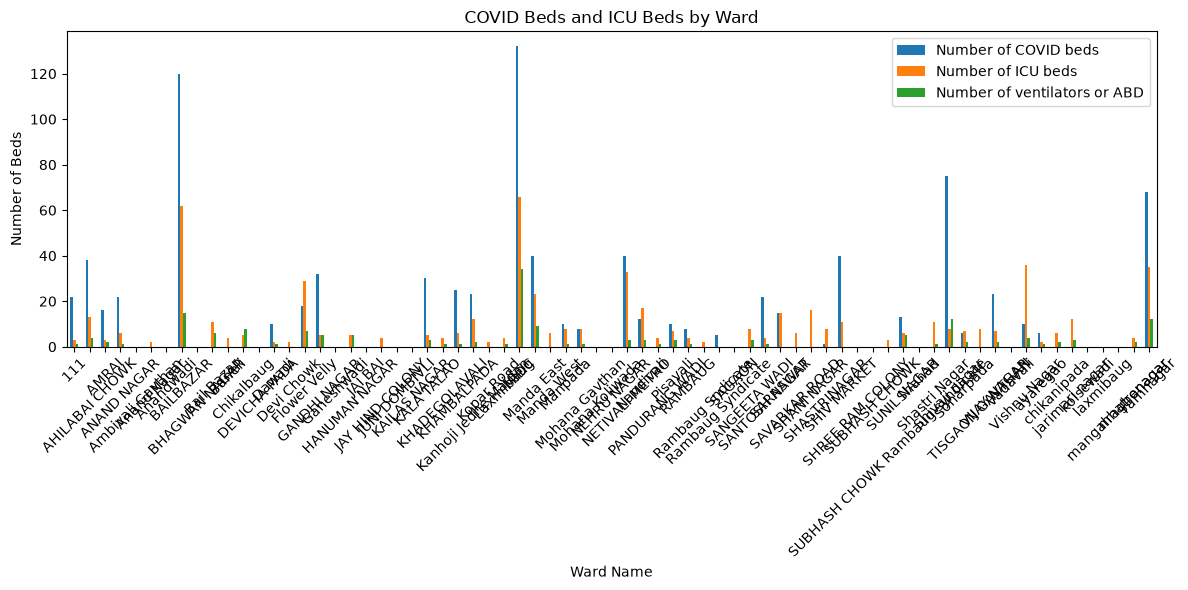

In [40]:
pivot_beds.plot(
    kind='bar',
    figsize=(12, 6),
    title='COVID Beds and ICU Beds by Ward'
)

import matplotlib.pyplot as plt

plt.ylabel('Number of Beds')
plt.xlabel('Ward Name')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [42]:
melt_df = df[
    [
        'Ward Name',
        'Number of COVID beds',
        'Number of ICU beds',
        'Number of ventilators or ABD'
    ]
].copy()

display(melt_df.head())


,Ward Name,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD
0,Kopar Road,NaN,NaN,NaN
1,Vishnu Nagar,NaN,6.0,NaN
2,Vishnu Nagar,NaN,4.0,1.0
3,Vishnu Nagar,10.0,9.0,3.0
4,Kanhoji Jedhe Maidan,8.0,4.0,NaN


In [44]:
melted_data = pd.melt(
    melt_df,
    id_vars=['Ward Name'],
    var_name='Bed Type',
    value_name='Count'
)

display(melted_data.head(10))

,Ward Name,Bed Type,Count
0,Kopar Road,Number of COVID beds,NaN
1,Vishnu Nagar,Number of COVID beds,NaN
2,Vishnu Nagar,Number of COVID beds,NaN
3,Vishnu Nagar,Number of COVID beds,10.0
4,Kanhoji Jedhe Maidan,Number of COVID beds,8.0
5,Vishnu Nagar,Number of COVID beds,NaN
6,Kanhoji Jedhe Maidan,Number of COVID beds,15.0
7,Vishnu Nagar,Number of COVID beds,0.0
8,Vishnu Nagar,Number of COVID beds,0.0
9,Kopar Road,Number of COVID beds,0.0


In [46]:
print("Original Shape:", melt_df.shape)

print("Melted Shape:", melted_data.shape)

print("\nColumn Names:")
print(melted_data.columns)

Original Shape: (182, 4)
Melted Shape: (546, 3)

Column Names:
Index(['Ward Name', 'Bed Type', 'Count'], dtype='str')


In [48]:
bed_summary = melted_data.groupby(
    'Bed Type'
)['Count'].sum().reset_index()

display(bed_summary)

,Bed Type,Count
0,Number of COVID beds,900.0
1,Number of ICU beds,587.0
2,Number of ventilators or ABD,170.0


In [51]:
result = (
    df[
        [
            'Ward Name',
            'Type of hospital_PrivateorPublic',
            'Number of COVID beds'
        ]
    ]
    .dropna()
    .groupby('Ward Name')['Number of COVID beds']
    .sum()
    .sort_values(ascending=False)
)

display(result.head(10))

Ward Name
MIDC              132.0
BAILBAZAR         120.0
Shivaji nagar      75.0
ramnagar           68.0
Manda East         40.0
NETIVALI METRO     40.0
SHIV MARKET        40.0
AHILABAI CHOWK     38.0
GANDHI NAGAR       32.0
KALA TALAO         30.0
Name: Number of COVID beds, dtype: float64

In [53]:
hospital_analysis = (
    df
    .groupby('Type of hospital_PrivateorPublic')['Number of COVID beds']
    .sum()
    .reset_index()
    .sort_values(
        by='Number of COVID beds',
        ascending=False
    )
)

display(hospital_analysis)

,Type of hospital_PrivateorPublic,Number of COVID beds
78,PRIVATE,102.0
79,RAILWAY HOSPITAL,75.0
100,SHREEDEVI HOSPITAL,52.0
145,noble hospital,45.0
0,AIMS HOSPITAL,45.0
...,...,...
151,sanjivani hospital,0.0
154,shree childrens hospital,0.0
152,sarth netralaya,0.0
155,shriram hospital,0.0


In [55]:
top_icu_wards = (
    df
    .groupby('Ward Name')['Number of ICU beds']
    .sum()
    .reset_index()
    .sort_values(
        by='Number of ICU beds',
        ascending=False
    )
    .head(10)
)

display(top_icu_wards)

,Ward Name,Number of ICU beds
29,MIDC,66.0
7,BAILBAZAR,62.0
62,Vishnu Nagar,36.0
70,ramnagar,35.0
36,NETIVALI METRO,33.0
15,Flower Velly,29.0
30,Manda East,23.0
37,Nandivali,17.0
48,SHANI NAGAR,16.0
46,SARASWAT,15.0


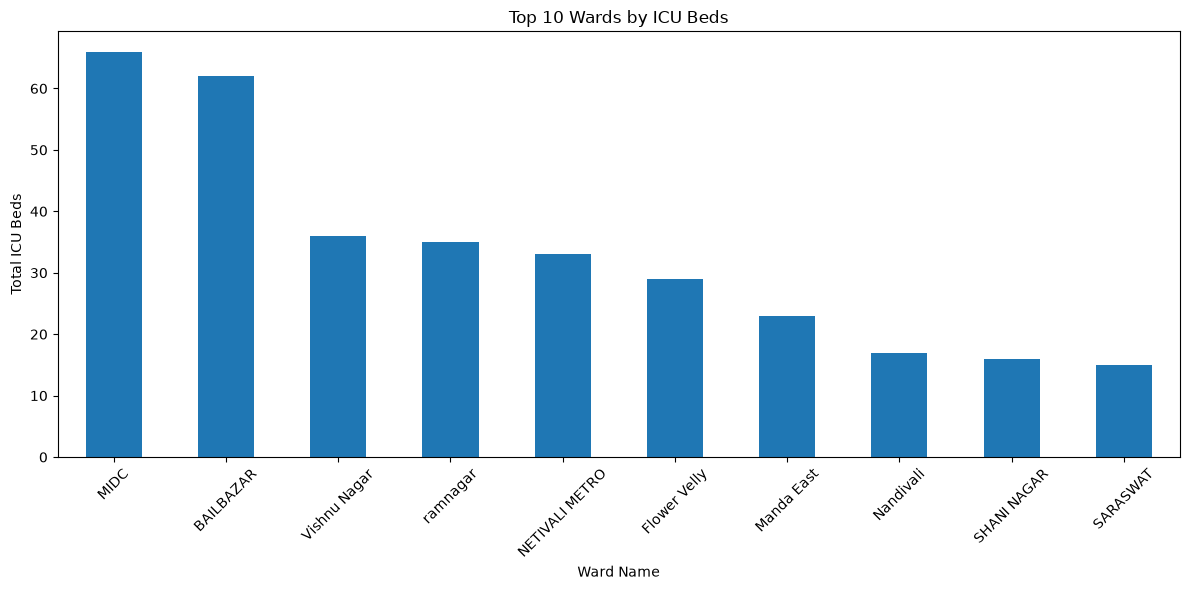

In [57]:
import matplotlib.pyplot as plt

top_icu_wards.plot(
    x='Ward Name',
    y='Number of ICU beds',
    kind='bar',
    figsize=(12, 6),
    legend=False,
    title='Top 10 Wards by ICU Beds'
)

plt.xlabel('Ward Name')
plt.ylabel('Total ICU Beds')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [58]:
print("TASK 1: MERGE")
print(inner_join.shape)

print("\nTASK 2: PIVOT TABLE")
print(pivot_beds.head())

print("\nTASK 3: MELT")
print(melted_data.shape)

print("\nTASK 4: METHOD CHAINING")
print(result.head())

print("\nAll four Pandas tasks completed!")

TASK 1: MERGE
(452, 11)

TASK 2: PIVOT TABLE
                  Number of COVID beds  Number of ICU beds  \
Ward Name                                                    
111                               22.0                 3.0   
AHILABAI CHOWK                    38.0                13.0   
AMRAI                             16.0                 3.0   
ANAND NAGAR                       22.0                 6.0   
Ambivali Gavthan                   0.0                 0.0   

                  Number of ventilators or ABD  
Ward Name                                       
111                                        1.0  
AHILABAI CHOWK                             4.0  
AMRAI                                      2.0  
ANAND NAGAR                                1.0  
Ambivali Gavthan                           0.0  

TASK 3: MELT
(546, 3)

TASK 4: METHOD CHAINING
Ward Name
MIDC             132.0
BAILBAZAR        120.0
Shivaji nagar     75.0
ramnagar          68.0
Manda East        40.0
Name